# Window Partitioning


In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
import torchvision


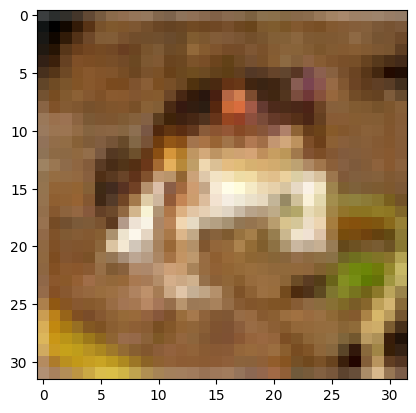

Partitioned shape: torch.Size([16, 8, 8, 3])


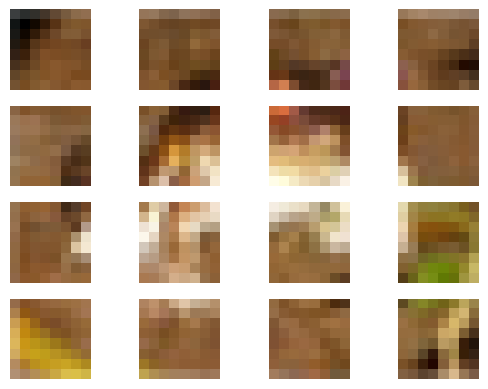

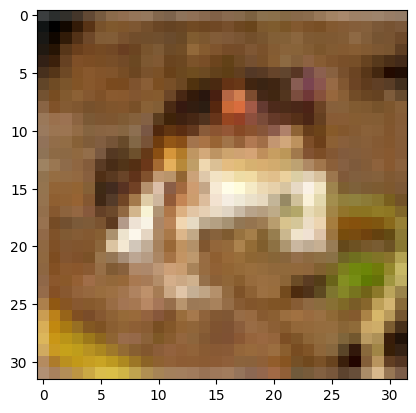

In [3]:
def window_partition(x, window_size):
    """
    x: [B, H, W, C]

    return:
        windows: [num_windows * B,
                  window_size,
                  window_size,
                  C]
    """
    B, H, W, C = x.shape
    h_num = H // window_size
    w_num = W // window_size
    windows = x.view(B, h_num, window_size, w_num, window_size, C)
    windows_permute = windows.permute(0, 1, 3, 2, 4, 5)
    windows_reshape = windows_permute.reshape(
        B * h_num * w_num, window_size, window_size, C
    )
    return windows_reshape


def window_reverse(windows, window_size, H, W):
    """
    Reverse window_partition.

    windows:
        [num_windows * B,
         window_size,
         window_size,
         C]

    return:
        x: [B, H, W, C]
    """
    h_num = H // window_size
    w_num = W // window_size
    B, C = windows.shape[0] / h_num / w_num, windows.shape[-1]
    B = int(B)

    x = windows.reshape(B, h_num, w_num, window_size, window_size, C)
    x_permute = x.permute(0, 1, 3, 2, 4, 5)
    x_reshape = x_permute.reshape(B, H, W, C)
    return x_reshape


x = torch.randn(2, 8, 8, 96)
x = torch.from_numpy(plt.imread("../data/cifar-10/train/1.png"))
plt.imshow(x.cpu().numpy())
plt.show()
x = x.unsqueeze(0)

w_size = 8

g_shape = x.shape[1] // w_size
x_partitioned = window_partition(x, w_size)

print("Partitioned shape:",x_partitioned.shape)
# torch.Size([8, 4, 4, 96])

for i in range(x_partitioned.shape[0]):
    plt.subplot(g_shape, g_shape, i + 1)
    plt.imshow(x_partitioned[i].cpu().numpy())
    plt.axis("off")
plt.show()

x_reconstructed = window_reverse(x_partitioned, w_size, x.shape[1], x.shape[2])
plt.imshow(x_reconstructed.cpu().numpy()[0])
plt.show()

In [31]:
window_size = 4

Xs = torch.arange(window_size)
Ys = torch.arange(window_size)

print(Xs)
print(Ys)

coords = torch.stack(torch.meshgrid([Xs, Ys], indexing="ij"))
coords_flatten = torch.flatten(coords, 1)
print(coords_flatten)

# relative_coords = coords_flatten.unsqueeze(2)-coords_flatten.unsqueeze(1)
relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
print("Relative coords shape:", relative_coords.shape)
# relative_coords = relative_coords.permute(1, 2, 0).contiguous()
# print("Reative coords shape after Permute:", relative_coords.shape)

relative_coords = relative_coords + window_size - 1

def mapping(x,y,window_size,coords):
    flattened_coords = coords.flatten()
    N = window_size**2
    n_x = flattened_coords[y * (N) + x]
    n_y = flattened_coords[N**2 + y * (window_size) + x]
    return n_x.item(),n_y.item()
x, y = 1, 0
print("Org_val\tVS Flattened\t\tDiff")
for x in range(16):
    print(f"Index of x,y:\t{x}, {y}")
    org_val = relative_coords[:, y, x].numpy()
    f_values = mapping(x,y,window_size,relative_coords)
    
    print(f"\t{org_val} :\t{f_values},\t\t{org_val-f_values}")
    

tensor([0, 1, 2, 3])
tensor([0, 1, 2, 3])
tensor([[0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3]])
Relative coords shape: torch.Size([2, 16, 16])
Org_val	VS Flattened		Diff
Index of x,y:	0, 0
	[3 3] :	(3, 3),		[0 0]
Index of x,y:	1, 0
	[3 2] :	(3, 2),		[0 0]
Index of x,y:	2, 0
	[3 1] :	(3, 1),		[0 0]
Index of x,y:	3, 0
	[3 0] :	(3, 0),		[0 0]
Index of x,y:	4, 0
	[2 3] :	(2, 3),		[0 0]
Index of x,y:	5, 0
	[2 2] :	(2, 2),		[0 0]
Index of x,y:	6, 0
	[2 1] :	(2, 1),		[0 0]
Index of x,y:	7, 0
	[2 0] :	(2, 0),		[0 0]
Index of x,y:	8, 0
	[1 3] :	(1, 3),		[0 0]
Index of x,y:	9, 0
	[1 2] :	(1, 2),		[0 0]
Index of x,y:	10, 0
	[1 1] :	(1, 1),		[0 0]
Index of x,y:	11, 0
	[1 0] :	(1, 0),		[0 0]
Index of x,y:	12, 0
	[0 3] :	(0, 3),		[0 0]
Index of x,y:	13, 0
	[0 2] :	(0, 2),		[0 0]
Index of x,y:	14, 0
	[0 1] :	(0, 1),		[0 0]
Index of x,y:	15, 0
	[0 0] :	(0, 0),		[0 0]
